# EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

### Se fija el path objetivo

In [2]:
current_path = Path().cwd()
target_dir = current_path.parent.joinpath("data","raw")
print(target_dir)

/home/jojo/Documentos/ML_IA/Pruebas_Tecnicas /constructora-costos/data/raw


Se leen csv's

In [3]:
historical_equipment = pd.read_csv(target_dir / 'historico_equipos.csv', parse_dates=['Date'])
historical_x = pd.read_csv(target_dir / 'X.csv', parse_dates=['Date'])
historical_y = pd.read_csv(target_dir / 'Y.csv', sep=';', decimal=',', parse_dates=['Date'])
historical_z = pd.read_csv(target_dir / 'Z.csv', parse_dates=['Date'])

In [4]:
print(f"train:{historical_equipment.shape}")
print(f"test:{historical_x.shape}")
print(f"test:{historical_y.shape}")
print(f"test:{historical_z.shape}")

train:(3530, 6)
test:(9144, 2)
test:(4485, 2)
test:(3565, 2)


Se crea una funcion para inspecionar nulos y fechas disponibles en los diferentes datos

In [5]:
def inspect_df(df:pd.DataFrame, name:str) -> None:
  """
  Function 
  """
  print(f"{name}")
  print(f"shape:{df.shape}")
  print(f"Period: {df.select_dtypes('datetime64').min().values} "
        f"to {df.select_dtypes('datetime64').max().values}"
        if not df.select_dtypes('datetime64').empty else "")
  print("Columns and types:")
  print(df.dtypes)
  print("\nNulls:")
  nulls = df.isnull().sum()
  print(nulls[nulls > 0] if nulls.any() else "  Sin nulos")
  print("\nFirst rows:")
  display(df.head(3))
  print("\nLast rows:")
  display(df.tail(3))
  print(f"{'='*40}")

Con la inspeccion se detecta un problema de formato de fecha por lo que se procede a corregir

In [6]:
historical_y['Date'] = pd.to_datetime(historical_y['Date'], format='%d/%m/%Y')

In [7]:
inspect_df(historical_equipment,'historico_equipos.csv')
inspect_df(historical_x,'X.csv')
inspect_df(historical_y,'Y.csv')
inspect_df(historical_z,'Z.csv')

historico_equipos.csv
shape:(3530, 6)
Period: ['2010-01-04T00:00:00.000000'] to ['2023-08-31T00:00:00.000000']
Columns and types:
Date             datetime64[us]
Price_X                 float64
Price_Y                 float64
Price_Z                 float64
Price_Equipo1           float64
Price_Equipo2           float64
dtype: object

Nulls:
  Sin nulos

First rows:


,Date,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
0,2010-01-04,80.12,527.5,2225.25,434.73,931.73
1,2010-01-05,80.59,527.5,2246.50,449.97,968.56
2,2010-01-06,81.89,527.5,2302.50,444.48,960.51



Last rows:


,Date,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
3527,2023-08-29,85.49,545.33,2116.25,460.42,901.79
3528,2023-08-30,85.86,543.67,2140.25,464.80,945.40
3529,2023-08-31,86.86,545.00,2165.25,451.73,955.35


X.csv
shape:(9144, 2)
Period: ['1988-06-27T00:00:00.000000'] to ['2024-04-04T00:00:00.000000']
Columns and types:
Date     datetime64[us]
Price           float64
dtype: object

Nulls:
  Sin nulos

First rows:


...

,Date,Price
4482,2006-07-13,555.0
4483,2006-07-12,555.0
4484,2006-07-11,555.0


Z.csv
shape:(3565, 2)
Period: ['2010-01-01T00:00:00.000000'] to ['2023-08-31T00:00:00.000000']
Columns and types:
Price           float64
Date     datetime64[us]
dtype: object

Nulls:
  Sin nulos

First rows:


,Price,Date
0,2225.25,2010-01-01
1,2225.25,2010-01-04
2,2246.50,2010-01-05



Last rows:


,Price,Date
3562,2116.25,2023-08-29
3563,2140.25,2023-08-30
3564,2165.25,2023-08-31


Formateo de los datos, columna de data pasa a ser primer columna y se hace un sort de acuerdo a la ultima fecha

In [8]:
def df_normalitation(df:pd.DataFrame, date_col='Date') -> pd.DataFrame:
    """
    Order datetime values and
    Pass the column Date to the first column
    """
    df = df.sort_values(by=date_col, ascending=False).reset_index(drop=True)
    columns = [date_col] + [col for col in df.columns if col != date_col]
    df = df[columns]
    
    return df

In [9]:
df_equipment_norm = df_normalitation(historical_equipment)
df_x_norm = df_normalitation(historical_x)
df_y_norm = df_normalitation(historical_y)
df_z_norm = df_normalitation(historical_z)

In [10]:
df_equipment_norm.head()

,Date,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
0,2023-08-31,86.86,545.00,2165.25,451.73,955.35
1,2023-08-30,85.86,543.67,2140.25,464.80,945.40
2,2023-08-29,85.49,545.33,2116.25,460.42,901.79
3,2023-08-28,84.42,549.00,2116.25,469.03,933.20
4,2023-08-25,84.48,554.00,2123.50,450.36,899.65


In [11]:
def validate_historical_col(
    df_indiv: pd.DataFrame, 
    df_hist: pd.DataFrame, 
    indiv_col: str, 
    hist_col: str, 
    df_name: str
) -> None:
    """
    Validates that values from the individual artifacts match with historical 
    column data, using date as index
    """
    s1 = df_indiv.set_index('Date')[indiv_col]
    s2 = df_hist.set_index('Date')[hist_col]

    comp_df = pd.DataFrame({
        'Individual': s1,
        'Historical': s2
    }).dropna()

    are_close = np.isclose(comp_df['Individual'], comp_df['Historical'], rtol=1e-5, atol=1e-8)

    print(f"-- Validation for {df_name} --")    
    if all(are_close):
        print(" All values match perfectly")
    else:
        dif  = comp_df[~are_close]
        print(f"It founds {len(dif)} discrepancies")
        display(dif.head(10))
    print(f"{'='*40}")

In [12]:
validate_historical_col(df_indiv=df_y_norm, df_hist=df_equipment_norm, indiv_col='Price', hist_col='Price_Y', 
    df_name='Y_df')
validate_historical_col(df_indiv=df_x_norm, df_hist=df_equipment_norm, indiv_col='Price', hist_col='Price_X', 
    df_name='X_df')
validate_historical_col(df_indiv=df_z_norm, df_hist=df_equipment_norm, indiv_col='Price', hist_col='Price_Z', 
    df_name='Z_df')

-- Validation for Y_df --
 All values match perfectly
-- Validation for X_df --
 All values match perfectly
-- Validation for Z_df --
 All values match perfectly


In [13]:
def check_date_gaps(df: pd.DataFrame, date_col: str = 'Date') -> pd.DatetimeIndex:
    """
    Checks for missing business days (excluding weekends) in the DataFrame 
    between the minimum and maximum dates.
    """
    df = df.copy()
    start_date = df[date_col].min()
    end_date = df[date_col].max()
    expected_business_days = pd.bdate_range(start=start_date, end=end_date)
    
    actual_dates = pd.DatetimeIndex(df[date_col])
    missing_dates = expected_business_days.difference(actual_dates)
    
    print("--- Date Gap Analysis ---")
    print(f"Start date: {start_date.strftime('%Y-%m-%d')}")
    print(f"End date:   {end_date.strftime('%Y-%m-%d')}")
    print(f"Expected business days: {len(expected_business_days)}")
    print(f"Actual records found:   {len(actual_dates)}")
    
    if len(missing_dates) == 0:
        print("No Gaps found")
    else:
        print(f"It founds {len(missing_dates)} missing business days:")
        display(pd.DataFrame({'Missing_Business_Date': missing_dates}).head(15))
    
    return missing_dates

In [14]:
missing_days = check_date_gaps(df_equipment_norm, date_col='Date')

--- Date Gap Analysis ---
Start date: 2010-01-04
End date:   2023-08-31
Expected business days: 3564
Actual records found:   3530
It founds 34 missing business days:


,Missing_Business_Date
0,2010-04-02
1,2011-04-22
2,2011-12-26
3,2012-01-02
4,2012-04-06
5,2012-12-25
6,2013-01-01
7,2013-03-29
8,2013-12-25
9,2014-04-18


In [15]:
def plot_equipment_prices(df: pd.DataFrame, date_col: str = 'Date') -> None:
    """
    Plots each time series in diferent supbplot, with date as X-axis
    """
    df = df.copy()
    df = df.sort_values(by=date_col)
    
    price_columns = [col for col in df.columns if col != date_col]
    n_cols = len(price_columns)
    
    _, axes = plt.subplots(n_cols, 1, figsize=(12, 2.5 * n_cols), sharex=True)
    
    if n_cols == 1:
        axes = [axes]
        
    for i, col in enumerate(price_columns):
        ax = axes[i]
        ax.plot(df[date_col], df[col], label=col, color='tab:orange', linewidth=1.2)
        ax.set_ylabel(col, fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='upper left')
        
    plt.suptitle('Historical Prices by Equipment / Series', fontsize=14, y=0.98)
    plt.xlabel('Date', fontsize=11)
    plt.tight_layout()
    plt.savefig('../notebooks/figures/01_Historical_Prices_by_Equipment_series.png',dpi=150)
    plt.show()


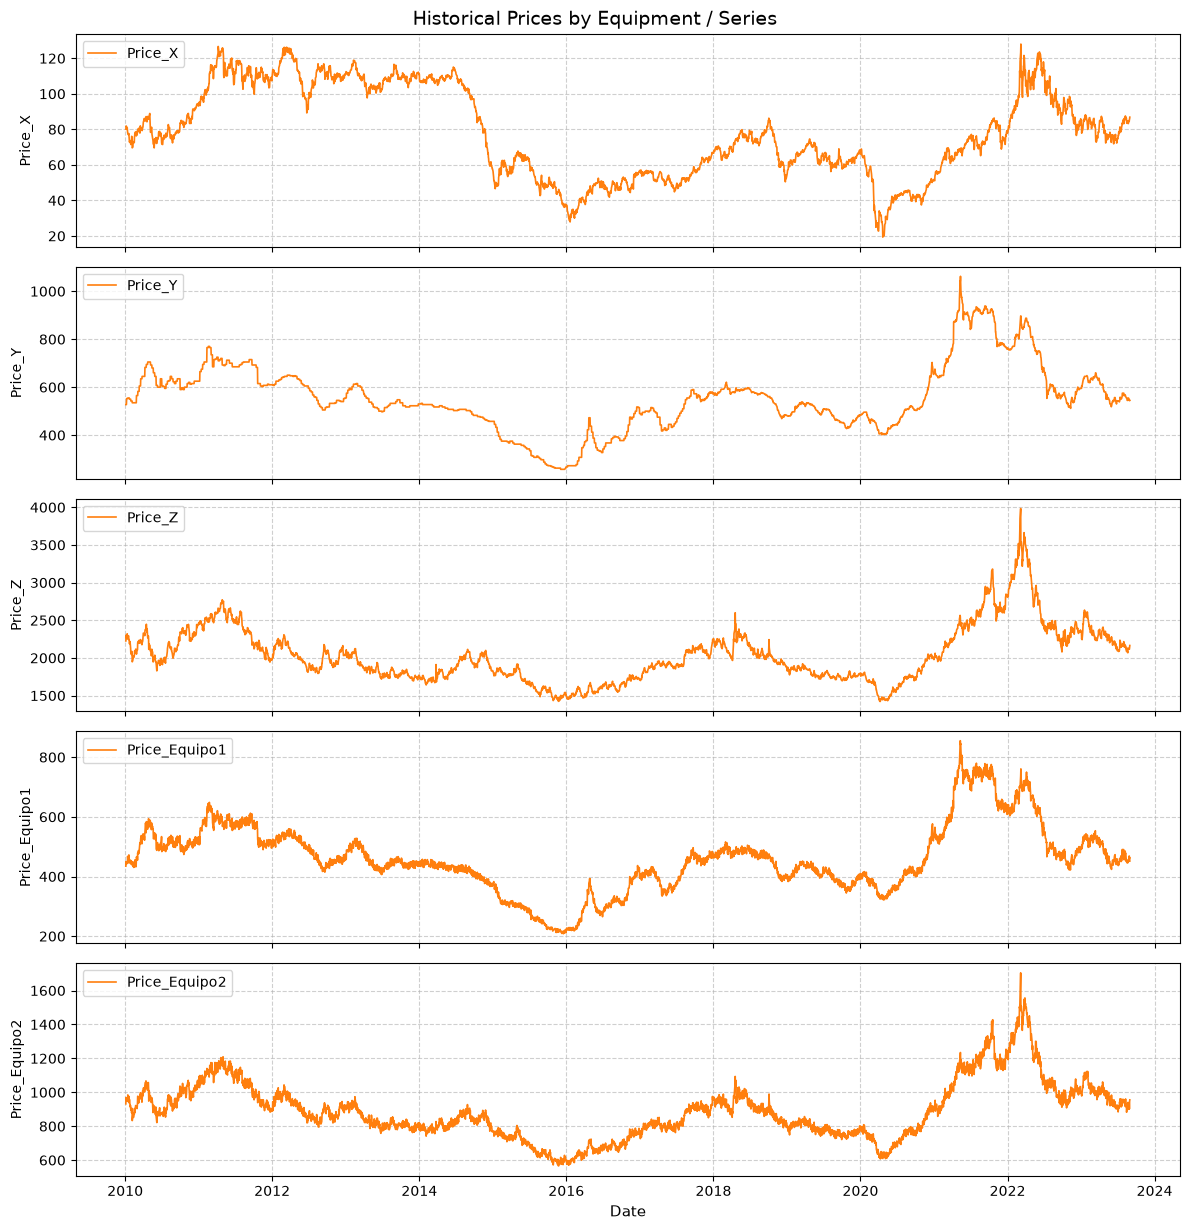

In [35]:
plot_equipment_prices(df_equipment_norm, date_col='Date')

In [17]:
def descriptive_stadistic(df: pd.DataFrame, date_col: str = 'Date') -> pd.DataFrame:
    """
    Calculates Spearman correlation matrix and plot heatmap
    """
    df = df.copy()
    numeric_df = df.drop(columns=[date_col], errors='ignore').select_dtypes(include='number')

    stats = numeric_df.describe().T
    stats['median'] = numeric_df.median()
    stats['skewness'] = numeric_df.skew()
    stats['iqr'] = numeric_df.quantile(0.75) - numeric_df.quantile(0.25)

    print("--- Descriptive Statistics Summary ---")
    display(stats)

    return stats

In [18]:
summary_stats = descriptive_stadistic(df_equipment_norm)

--- Descriptive Statistics Summary ---


,count,mean,std,min,25%,50%,75%,max,median,skewness,iqr
Price_X,3530.0,78.091014,25.186945,19.33,57.0525,75.400,104.5825,127.98,75.400,0.079363,47.5300
Price_Y,3530.0,555.527108,138.489003,257.50,482.5000,541.625,620.0000,1062.37,541.625,0.480273,137.5000
Price_Z,3530.0,2037.432073,373.140448,1421.50,1767.2500,1974.750,2235.9375,3984.00,1974.750,1.135788,468.6875
Price_Equipo1,3530.0,460.036901,113.681273,208.34,398.2275,451.250,515.6075,855.32,451.250,0.411426,117.3800
Price_Equipo2,3530.0,889.980408,170.042689,566.00,777.7025,869.785,979.1225,1703.96,869.785,0.833780,201.4200


In [19]:
def plot_equipment_distributions(df: pd.DataFrame, date_col: str = 'Date') -> None:
    """
    Plots the distribution histograms with KDE in diferent subplots
    """
    df = df.copy()
    numeric_df = df.drop(columns=[date_col], errors='ignore').select_dtypes(include='number')
    n_cols = len(numeric_df.columns)
    
    _, axes = plt.subplots(n_cols, 1, figsize=(10, 2.5 * n_cols))
    
    if n_cols == 1:
        axes = [axes]
        
    for i, col in enumerate(numeric_df.columns):
        ax = axes[i]
        
        sns.histplot(
            numeric_df[col].dropna(), 
            kde=True, 
            ax=ax, 
            color='tab:green', 
            bins='fd', 
            alpha=0.6
        )
        
        ax.set_title(f'Distribution of {col}', fontsize=11, fontweight='bold')
        ax.set_xlabel('Price Value', fontsize=10)
        ax.set_ylabel('Count', fontsize=10)
        ax.grid(True, linestyle='--', alpha=0.5)
        
    plt.suptitle('Price Distributions by Equipment / Series', fontsize=14, y=0.98)
    plt.tight_layout()
    plt.savefig('../notebooks/figures/02_DistributionsonTime.png',dpi=150)
    plt.show()

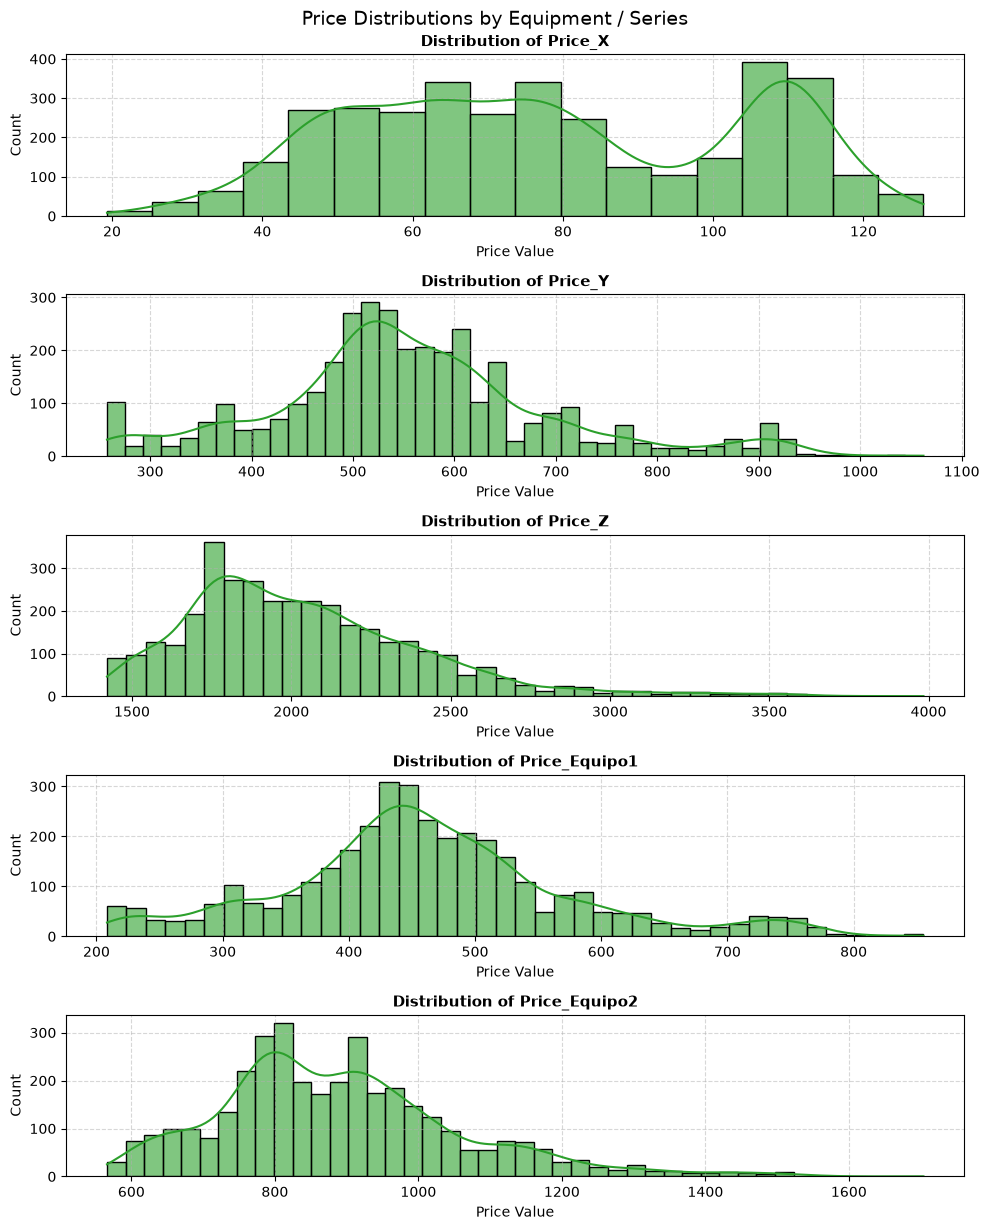

In [36]:

plot_equipment_distributions(df_equipment_norm, date_col='Date')

In [21]:
def plot_full_pairplot(df: pd.DataFrame, date_col: str = 'Date', title : str = 'Raw Data' ) -> None:
    """
    Generates pairplot matrix in order to compare relatioships in prices
    """
    numeric_df = df.drop(columns=[date_col], errors='ignore').select_dtypes(include='number')
    
    g = sns.pairplot(numeric_df, kind='scatter', diag_kind='kde', corner=True, plot_kws={'alpha': 0.4, 's': 15})
    g.fig.suptitle(f'Pairwise Scatter Plot Matrix on {title}', y=1.02, fontsize=14)
    plt.savefig(f'../notebooks/figures/03_Paiplot_Matrix_{title}.png',dpi=150)
    plt.show()

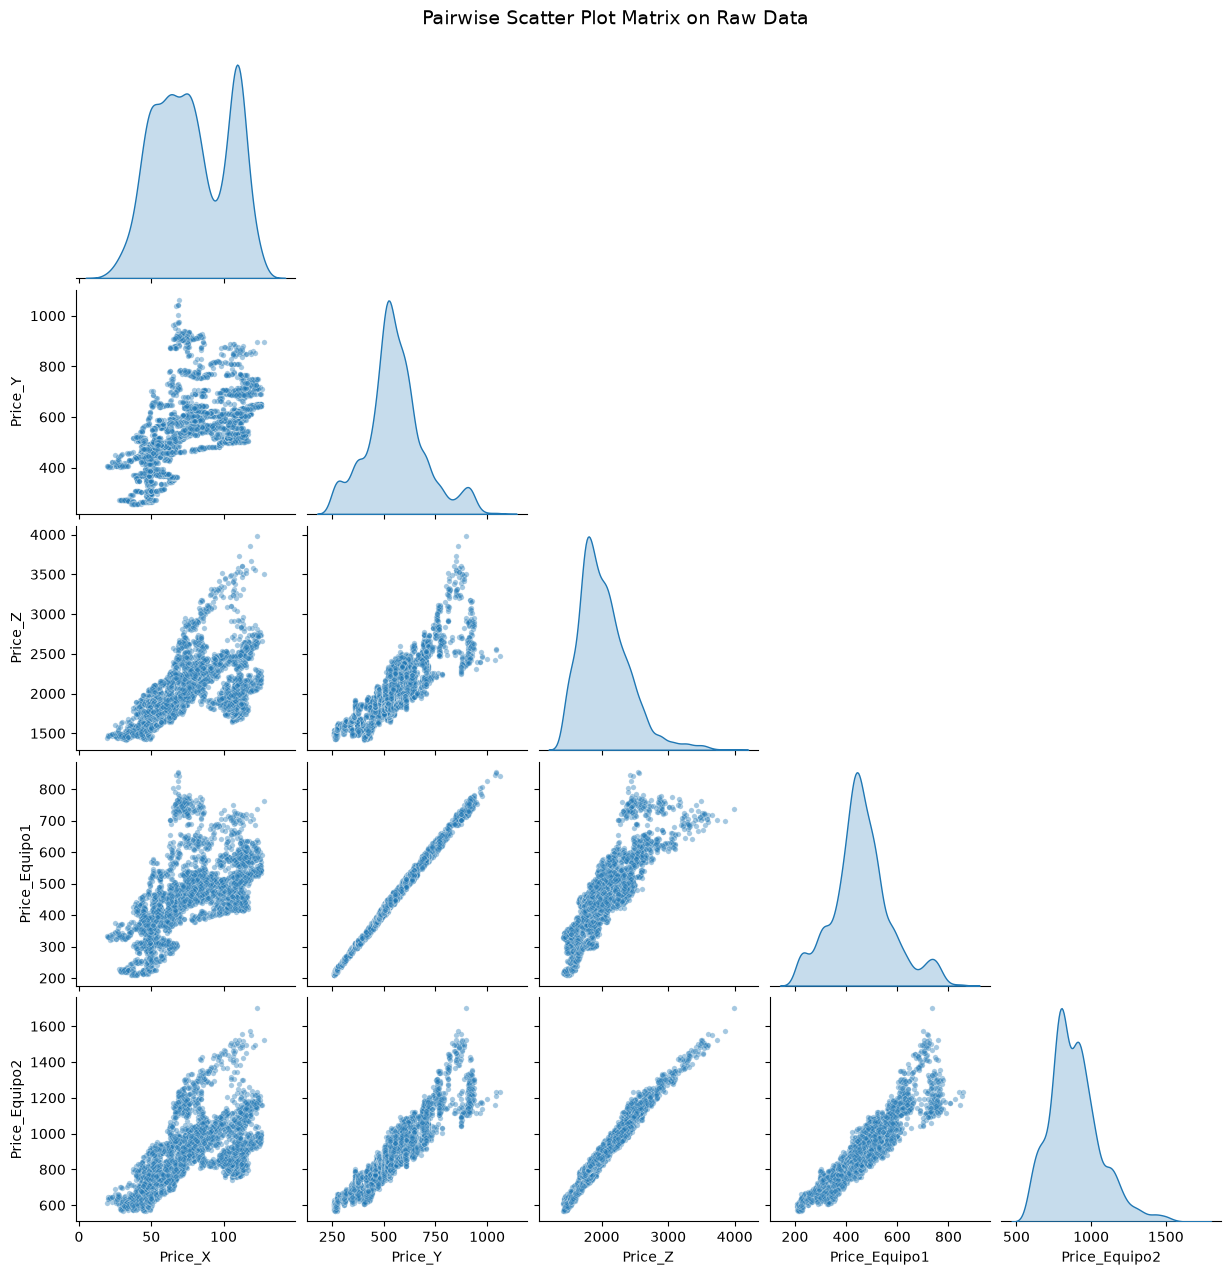

In [37]:
plot_full_pairplot(df_equipment_norm)

In [23]:
def calculate_and_plot_correlation(df: pd.DataFrame, date_col: str = 'Date', method = 'spearman',title : str = '(Raw)' ) -> pd.DataFrame:
    """
    Calculates Spearman correlation matrix and plot heatmap
    """
    df = df.copy()
    numeric_df = df.drop(columns=[date_col], errors='ignore').select_dtypes(include='number')
    corr_matrix = numeric_df.corr(method=method)
    
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        corr_matrix, 
        annot=True,        
        cmap='coolwarm',     
        vmin=-1, vmax=1,     
        fmt='.2f',           
        linewidths=0.5,     
        cbar_kws={'label': 'Spearman Rank Correlation Coefficient'}
    )
    
    plt.title(f'{method.capitalize()} Correlation Matrix of Equipment Prices {title}', fontsize=14, pad=15)
    plt.tight_layout()
    plt.savefig(f'../notebooks/figures/04_{method.capitalize()}_Heatmap_on_{title}_data.png',dpi=150)
    plt.show()
    
    return corr_matrix

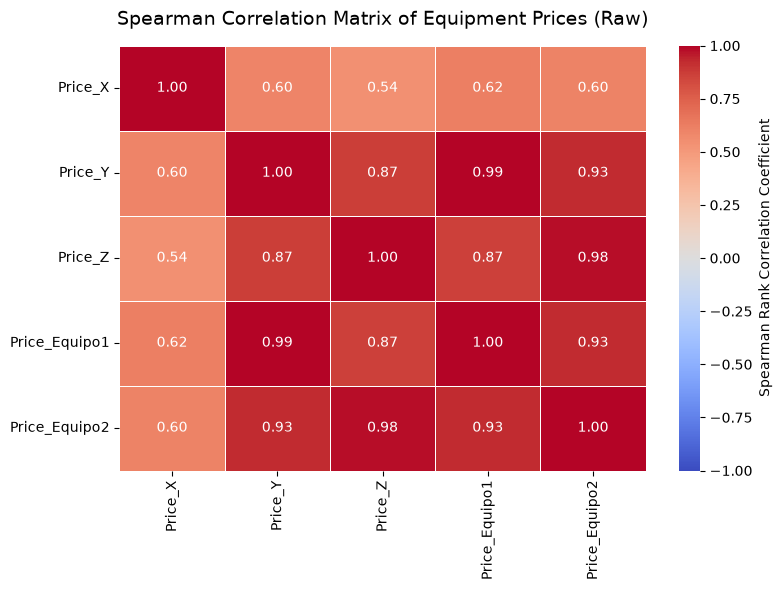

In [38]:
spearman_corr_df = calculate_and_plot_correlation(df_equipment_norm, date_col='Date')

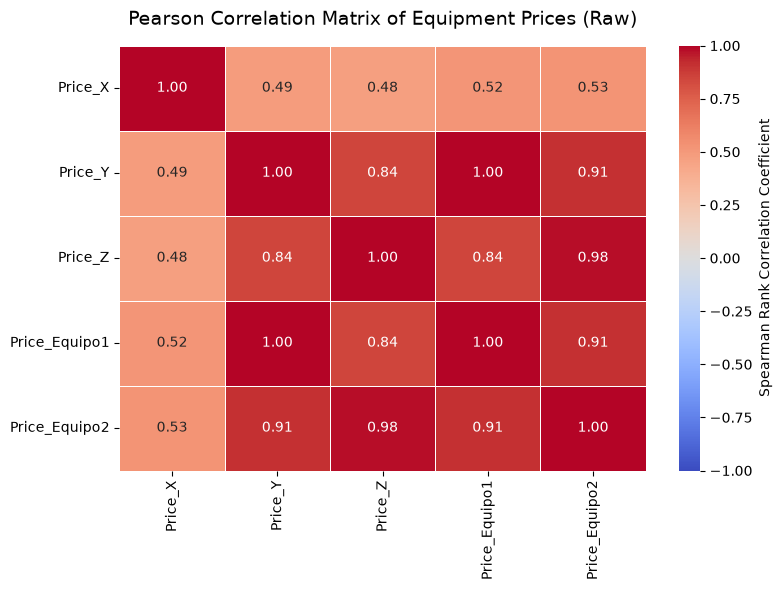

In [39]:
pearson_corr_df = calculate_and_plot_correlation(df_equipment_norm,date_col='Date',method='pearson')

In [26]:
def time_series_transformation(
    df:pd.DataFrame,
    date_col: str = 'Date',
    transform: str = 'pct_change'
) -> pd.DataFrame:
    """
    Apply a transformation, logaritmic or pct of chance into the time series
    """
    df = df.copy()
    numeric_cols = df.select_dtypes(include='number').columns

    transformed_df = df.copy()
    if transform == 'log':
        transformed_df[numeric_cols] = np.log(transformed_df[numeric_cols] / transformed_df[numeric_cols].shift(1))
    else:  
        transformed_df[numeric_cols] = transformed_df[numeric_cols].pct_change()

    transformed_df = transformed_df.dropna().reset_index(drop=True)

    return transformed_df

In [27]:
df_log_historical_equipment =  time_series_transformation(df_equipment_norm, date_col='Date', transform='log')
df_pct_historical_equipment = time_series_transformation(df_equipment_norm, date_col='Date', transform='pct_change')

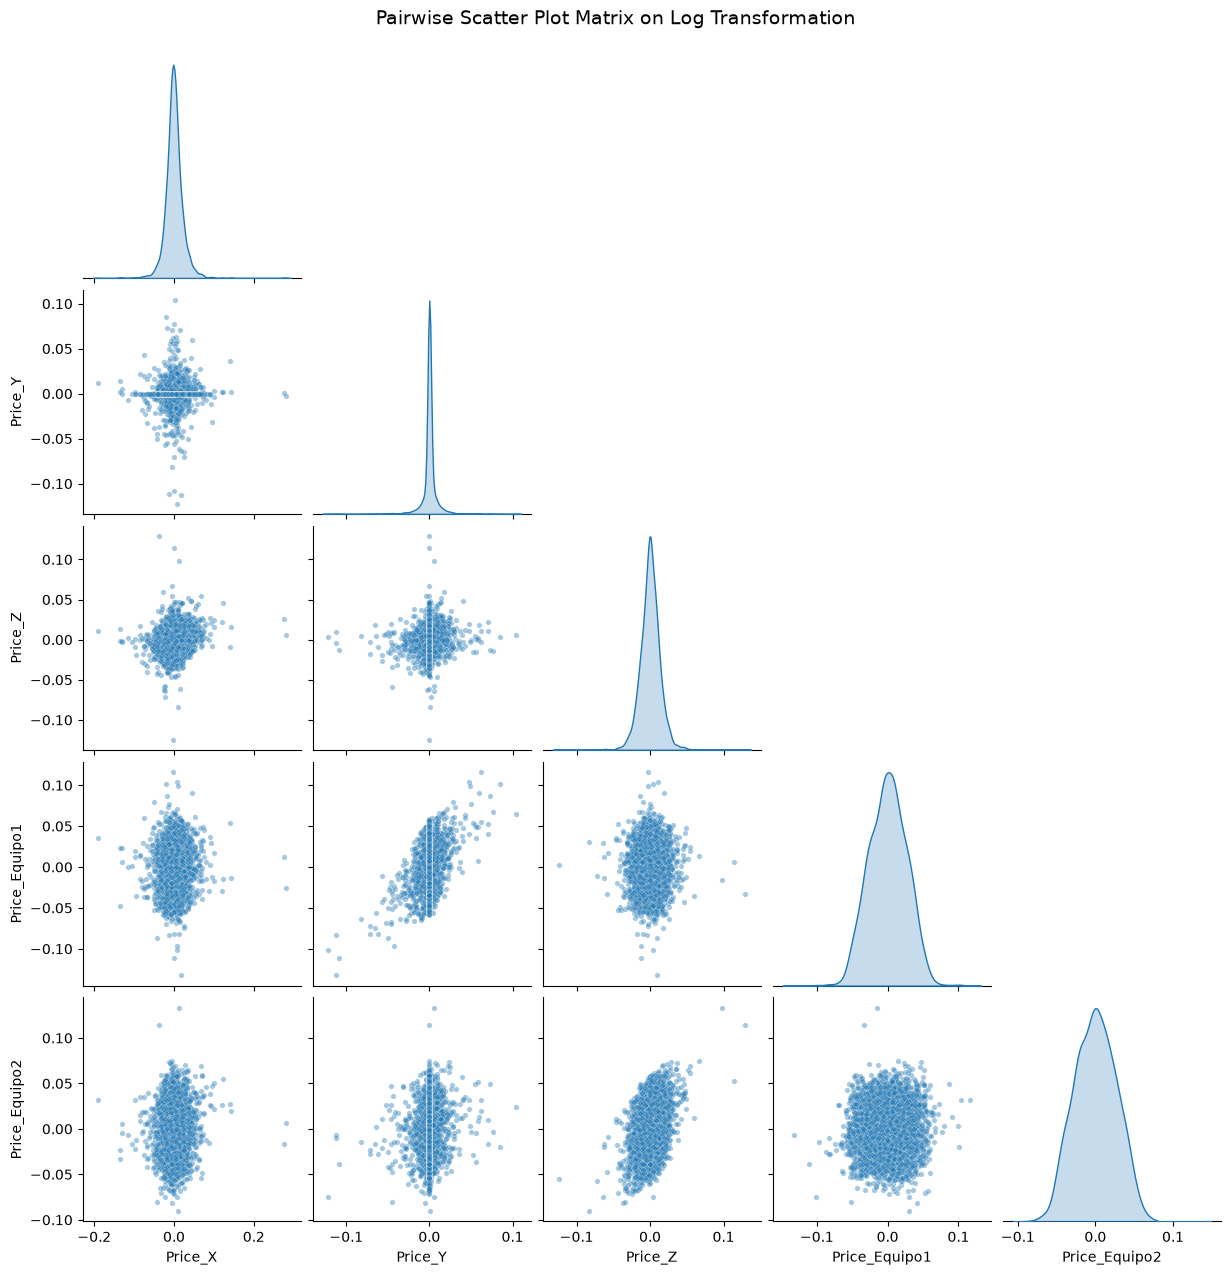

In [40]:
plot_full_pairplot(df_log_historical_equipment,title='Log Transformation')

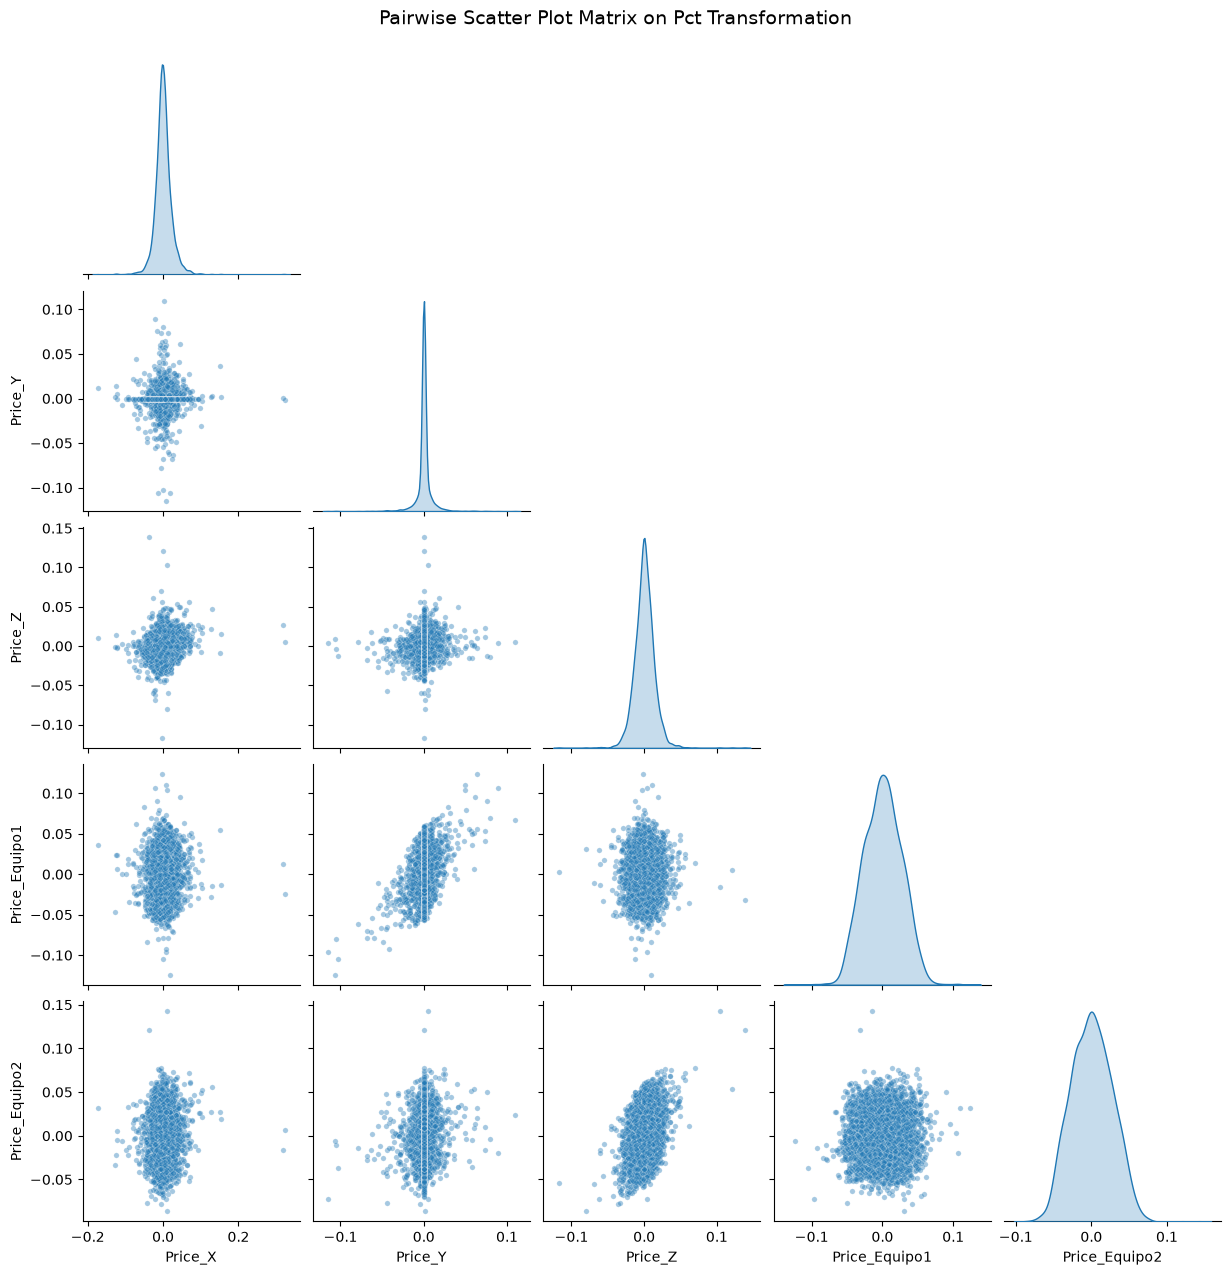

In [41]:
plot_full_pairplot(df_pct_historical_equipment,title='Pct Transformation')

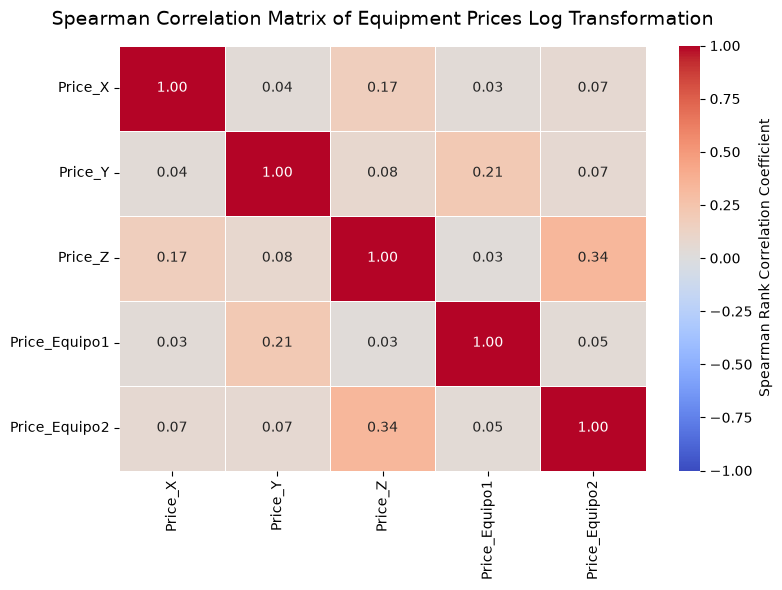

In [ ]:
pearson_corr_df_log = calculate_and_plot_correlation(
    df_log_historical_equipment, method='spearman',title='Log Transformation')

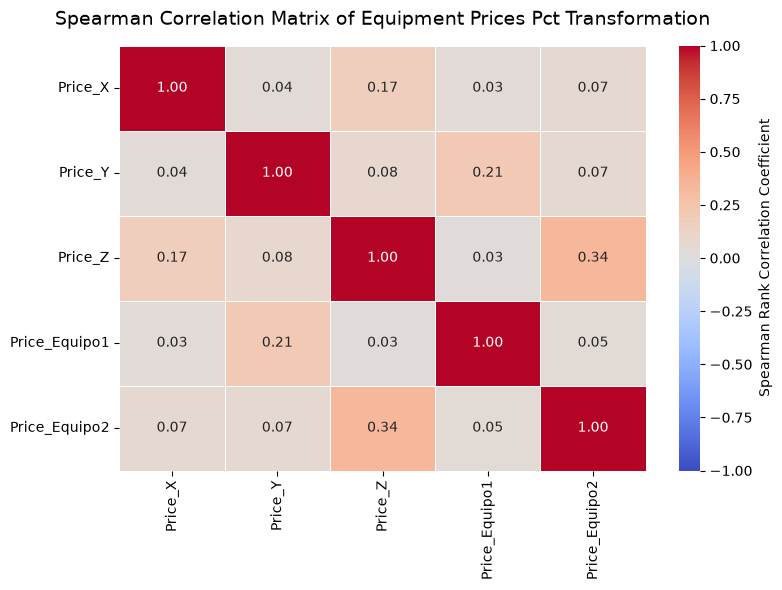

In [ ]:
pearson_corr_df_pct = calculate_and_plot_correlation(
    df_pct_historical_equipment, method='spearman',title='Pct Transformation')

In [44]:
from statsmodels.tsa.stattools import adfuller, kpss

In [ ]:

def evaluate_stationarity(df: pd.DataFrame, date_col: str = 'Date') -> pd.DataFrame:
    """
    Performs Augmented Dickey-Fuller (ADF) and KPSS tests on all numeric columns 
    to evaluate stationarity formally.
    """
    df = df.copy()
    
    numeric_df = df.drop(columns=[date_col], errors='ignore').select_dtypes(include='number')

    results = []
    
    for col in numeric_df.columns:
        series = numeric_df[col].dropna()

        # ADF Test
        adf_result = adfuller(series, autolag='AIC')
        adf_stat = adf_result[0]
        adf_pvalue = adf_result[1]
        is_adf_stationary = adf_pvalue < 0.05  
        
        # KPSSt Test  
        kpss_result = kpss(series, regression='c', nlags='auto')
            
        kpss_stat = kpss_result[0]
        kpss_pvalue = kpss_result[1]
        is_kpss_stationary = kpss_pvalue >= 0.05  
        
        results.append({
            'Column': col,
            'ADF Stat': adf_stat,
            'ADF p-value': adf_pvalue,
            'ADF Stationary (p<0.05)': is_adf_stationary,
            'KPSS Stat': kpss_stat,
            'KPSS p-value': kpss_pvalue,
            'KPSS Stationary (p>=0.05)': is_kpss_stationary
        })
        
    summary_df = pd.DataFrame(results).set_index('Column')
    
    print("--- Formal Stationarity Test Summary ---")
    display(summary_df)
    
    return summary_df

In [47]:
stacionary_levels_on_raw = evaluate_stationarity(df_equipment_norm, date_col='Date')

/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.

--- Formal Stationarity Test Summary ---


/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')


,ADF Stat,ADF p-value,ADF Stationary (p<0.05),KPSS Stat,KPSS p-value,KPSS Stationary (p>=0.05)
Column,,,,,,
Price_X,-1.724881,0.418341,False,2.690907,0.01,False
Price_Y,-2.518364,0.111070,False,1.375250,0.01,False
Price_Z,-2.182274,0.212742,False,1.462933,0.01,False
Price_Equipo1,-2.381196,0.147114,False,1.334858,0.01,False
Price_Equipo2,-1.887301,0.338059,False,1.409775,0.01,False


In [49]:
stacionary_levels_on_pct_transf = evaluate_stationarity(df_pct_historical_equipment)

/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.

--- Formal Stationarity Test Summary ---


/tmp/ipykernel_207595/1232265084.py:24: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')


,ADF Stat,ADF p-value,ADF Stationary (p<0.05),KPSS Stat,KPSS p-value,KPSS Stationary (p>=0.05)
Column,,,,,,
Price_X,-11.294081,1.357223e-20,True,0.062449,0.1,True
Price_Y,-10.111446,9.978582e-18,True,0.079794,0.1,True
Price_Z,-19.569544,0.000000e+00,True,0.063384,0.1,True
Price_Equipo1,-14.211112,1.720895e-26,True,0.070109,0.1,True
Price_Equipo2,-30.261102,0.000000e+00,True,0.068216,0.1,True


In [50]:
def analyze_lagged_correlations(
    df: pd.DataFrame, 
    predictor_cols: list, 
    target_col: str, 
    max_lags: int = 10, 
    date_col: str = 'Date',
    transform: str = 'pct_change'
) -> pd.DataFrame:
    """
    Calculates and plots lagged correlations between predictor variables and a target variable 
    using stationary transformations (returns).
    """
    df = df.copy()
    
    if pd.api.types.is_datetime64_any_dtype(df[date_col]):
        df = df.sort_values(by=date_col)
    numeric_cols = predictor_cols + [target_col]
    sub_df = df[numeric_cols].select_dtypes(include='number')
    
    if transform == 'log':
        trans_df = np.log(sub_df / sub_df.shift(1)).dropna()
    else: 
        trans_df = sub_df.pct_change().dropna()
            
    results = {}
    
    for col in predictor_cols:
        lag_corrs = []
        for lag in range(0, max_lags + 1):
            shifted_predictor = trans_df[col].shift(lag)
            corr = shifted_predictor.corr(trans_df[target_col])
            lag_corrs.append(corr)
        results[col] = lag_corrs
        
    lag_df = pd.DataFrame(results, index=[f'Lag_{i}' for i in range(max_lags + 1)])
    
    plt.figure(figsize=(10, 5))
    for col in predictor_cols:
        plt.plot(range(max_lags + 1), lag_df[col], marker='*', label=col, linewidth=1.5)
        
    plt.axhline(0, color='grey', linestyle='--', alpha=0.7)
    plt.title(f'Lagged Correlations of Predictors vs {target_col} ({transform.capitalize()} Returns)', fontsize=14, pad=15)
    plt.xlabel('Lag (Business Days in the past for Predictors)', fontsize=11)
    plt.ylabel('Correlation Coefficient', fontsize=11)
    plt.xticks(range(max_lags + 1))
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(title='Predictors')
    plt.tight_layout()
    plt.show()
    
    print(f"--- Summary Table of Lagged Correlations for {target_col} ---")
    display(lag_df.T)
    
    return lag_df

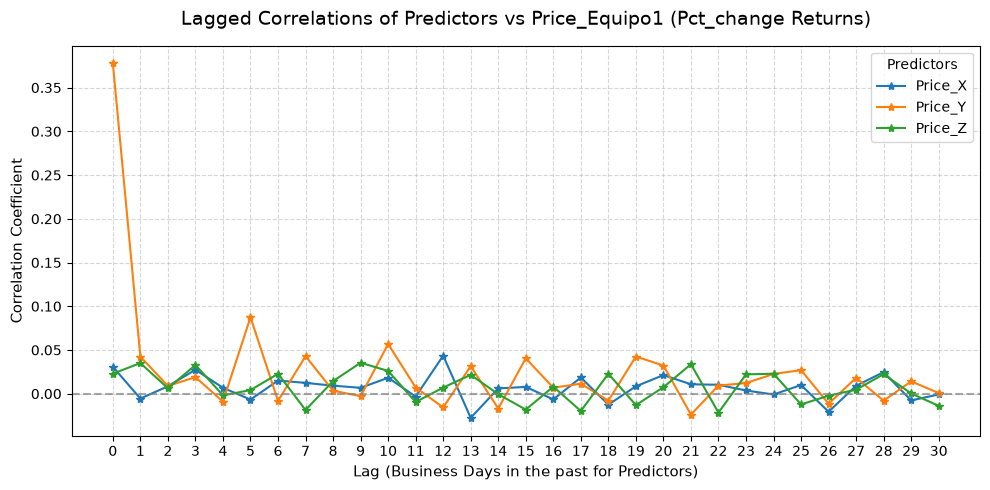

--- Summary Table of Lagged Correlations for Price_Equipo1 ---


,Lag_0,Lag_1,Lag_2,Lag_3,Lag_4,Lag_5,Lag_6,Lag_7,Lag_8,Lag_9,...,Lag_21,Lag_22,Lag_23,Lag_24,Lag_25,Lag_26,Lag_27,Lag_28,Lag_29,Lag_30
Price_X,0.030766,-0.005564,0.008476,0.027370,0.006770,-0.006715,0.015024,0.012351,0.009177,0.006713,...,0.010768,0.010171,0.003678,-0.000925,0.009917,-0.020650,0.009095,0.024676,-0.007762,-0.000840
Price_Y,0.377809,0.042378,0.008900,0.018931,-0.009074,0.087338,-0.008188,0.042898,0.003395,-0.002762,...,-0.023935,0.009293,0.012170,0.022528,0.026916,-0.011496,0.018166,-0.007971,0.014098,0.000787
Price_Z,0.022894,0.035018,0.006186,0.032756,-0.001863,0.004118,0.022755,-0.018665,0.014407,0.035374,...,0.033682,-0.021666,0.022087,0.022831,-0.012259,-0.002294,0.004588,0.022273,0.000220,-0.013891


In [54]:
predictors = ['Price_X', 'Price_Y', 'Price_Z']
target = 'Price_Equipo1'

lag_results_eq1 = analyze_lagged_correlations(
    df=df_equipment_norm, 
    predictor_cols=predictors, 
    target_col=target, 
    max_lags=30, 
    transform='pct_change'
)

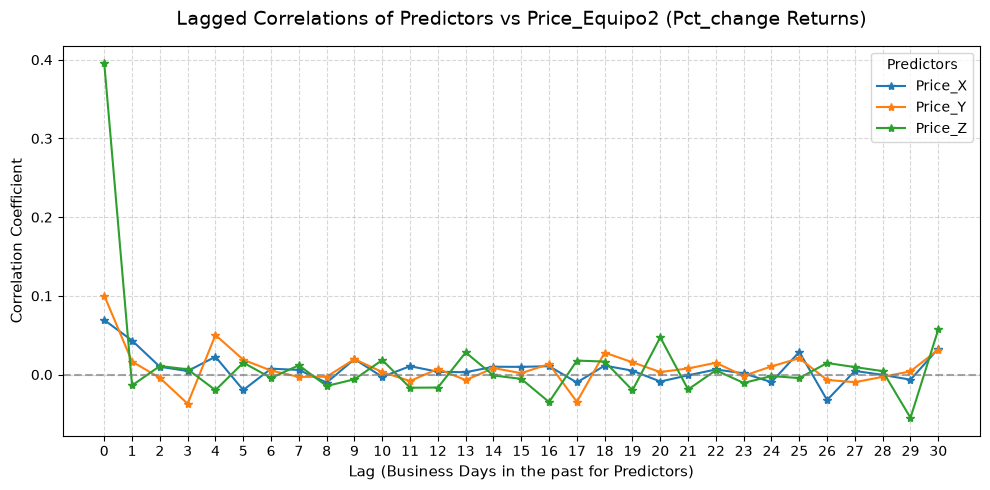

--- Summary Table of Lagged Correlations for Price_Equipo2 ---


,Lag_0,Lag_1,Lag_2,Lag_3,Lag_4,Lag_5,Lag_6,Lag_7,Lag_8,Lag_9,...,Lag_21,Lag_22,Lag_23,Lag_24,Lag_25,Lag_26,Lag_27,Lag_28,Lag_29,Lag_30
Price_X,0.069387,0.043239,0.009944,0.004522,0.022697,-0.019620,0.007515,0.005906,-0.010170,0.019639,...,-0.000917,0.006510,0.001588,-0.009562,0.028811,-0.032386,0.004667,-0.000385,-0.006475,0.033031
Price_Y,0.100434,0.016547,-0.004216,-0.037009,0.050347,0.018887,0.005084,-0.002898,-0.002687,0.019635,...,0.007789,0.015000,-0.001559,0.010430,0.020800,-0.006841,-0.009640,-0.002862,0.004186,0.031833
Price_Z,0.395457,-0.013780,0.010856,0.006773,-0.019796,0.015165,-0.004252,0.011810,-0.014470,-0.005982,...,-0.018883,0.005514,-0.010599,-0.001844,-0.004431,0.014714,0.009543,0.004383,-0.054925,0.057483


In [53]:
predictors = ['Price_X', 'Price_Y', 'Price_Z']
target = 'Price_Equipo2'

lag_results_eq2 = analyze_lagged_correlations(
    df=df_equipment_norm, 
    predictor_cols=predictors, 
    target_col=target, 
    max_lags=30, 
    transform='pct_change'
)